This notebook reproduces Fig. 17. We study the minimum infidelity for a filtered pulse (see `Fig08-optimal_nplus.ipynb` for more information) versus the pure dephasing time $T_2$ and the boundary condition of the driving pulse, with $z(t_\mathrm{f})=-z(t=0)$. Energies are given in units of $x$, and times in units of $\hbar/x$. The cut-off frequency is $f_c=x/\hbar$. In panel (a), $z(t=0)/x=-10$, while in panel (b), $T_2=100\,\hbar/x$.

The pulses are padded with constant tails at their initial and final values, $z(t=0)$ and $z(t_\mathrm{f})$, before filtering, such that the padded pulse is continuous, and the initial and target states are the ground states of the Hamiltonian at $z(t=0)$ and $z(t_\mathrm{f})$, respectively.

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from parameterrun import parameterrun

from HQUAD_lib.physics_utils import fidelity_LZ, filter_pulse
from HQUAD_lib.plotting_utils import add_labels
from HQUAD_lib.QUAD_utils import solve_LZ

In [2]:
x = 1
fc = 1

dynamics_reduction = (
    1  # The filtered pulse has 2 ** 14 + 1 points, as in the manuscript
)
tails_factor = 5

order = 3

n_values = 41  # Increase to get higher resolution (200 values in the manuscript)
n_minus = 0
n_plus = np.linspace(0, 5, n_values)

alphas = n_plus + n_minus
betas = n_plus - n_minus

n_tf = 100  # Increase to get higher resolution (200 values in the manuscript)
tf_list = np.linspace(1, 30, n_tf) * (1 + 2 / tails_factor)

In [3]:
def compute_fidelity_total(
    alpha: float, beta: float, gamma: float, z0: float
) -> np.ndarray:
    z_sol = solve_LZ(alpha, beta, reduction=dynamics_reduction, z0=z0)

    # Constant tails at the initial (z0) and final (-z0) values of the pulse
    boundary_left = np.ones(len(z_sol) // tails_factor) * z0
    boundary_right = np.ones(len(z_sol) // tails_factor) * -z0
    pulse = np.concatenate((boundary_left, z_sol, boundary_right))

    fidelities = np.zeros(n_tf)
    for i in range(n_tf):
        time = np.linspace(0, tf_list[i], len(pulse))
        filtered_pulse = filter_pulse(pulse, time, order=order, fc=fc)
        fidelities[i] = fidelity_LZ(z0, filtered_pulse, tf_list[i], x=x, gamma=gamma)

    return fidelities

# Run in $T_2$

In [4]:
z0 = -10

n_gamma = 20  # Increase to get higher resolution (100 values in the manuscript)
gamma_list = np.logspace(-3, -1, n_gamma)

gamma_fidelities = np.asarray(
    parameterrun(
        compute_fidelity_total,
        [["alpha", "beta"], ["gamma"]],
        [[alphas, betas], [gamma_list]],
        z0=z0,
    )
)

gamma_fidelities = gamma_fidelities.reshape((n_values, n_gamma, n_tf))
gamma_max_fidelity = np.max(gamma_fidelities, axis=-1)

compute_fidelity_total: [['alpha', 'beta(...)]:   0%|          | 0/820 [00:00<?, ?it/s]

# Run in $z(t=0)$

In [5]:
gamma = 0.005
print(f"T_2 = {1 / (2 * gamma):.0f} hbar / x")

n_z0 = 20  # Increase to get higher resolution (100 values in the manuscript)
z0_list = np.linspace(-20, -5, n_z0)

z0_fidelities = np.asarray(
    parameterrun(
        compute_fidelity_total,
        [["alpha", "beta"], ["z0"]],
        [[alphas, betas], [z0_list]],
        gamma=gamma,
    )
)

z0_fidelities = z0_fidelities.reshape((n_values, n_z0, n_tf))
z0_max_fidelity = np.max(z0_fidelities, axis=-1)

T_2 = 100 hbar / x


compute_fidelity_total: [['alpha', 'beta(...)]:   0%|          | 0/820 [00:00<?, ?it/s]

# Plot

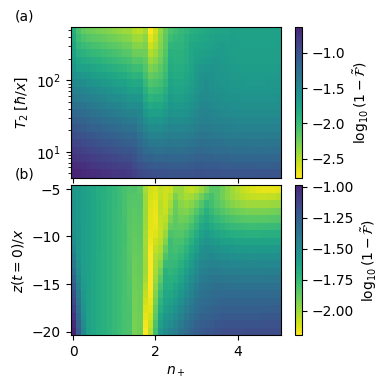

In [6]:
cmap_fidelity = ListedColormap(mpl.colormaps["viridis_r"](np.linspace(0, 0.9, 256)))

fig, axs = plt.subplots(2, 1, sharex=True, figsize=(3.4, 4))

T2 = 1 / (2 * gamma_list)
im0 = axs[0].pcolormesh(
    n_plus, T2, np.log10(1 - gamma_max_fidelity.T), cmap=cmap_fidelity, rasterized=True
)

axs[0].set_ylabel(r"$T_2 \;[\hbar / x]$")
axs[0].set_yscale("log")

im1 = axs[1].pcolormesh(
    n_plus,
    z0_list,
    np.log10(1 - z0_max_fidelity.T),
    cmap=cmap_fidelity,
    rasterized=True,
)

axs[1].set_xlabel(r"$n_+$")
axs[1].set_ylabel(r"$z(t=0) / x$")

plt.colorbar(im0, ax=axs[0], label=r"$\log_{10}(1 - \tilde{\mathcal{F}})$")
plt.colorbar(im1, ax=axs[1], label=r"$\log_{10}(1 - \tilde{\mathcal{F}})$")

fig.subplots_adjust(hspace=0.05)
add_labels(axs, [-0.22, 1.07])